# Project No. 3: Sentiment Analysis RELOADED — Clásico Tapatío (Chivas vs. Atlas)

Este notebook implementa de principio a fin el flujo completo de **Análisis de Sentimiento y Posturas Antagónicas (Chivas vs. Atlas)** sobre comentarios de redes sociales (YouTube), estructurado de forma modular y **sin repetir importaciones de librerías ni redefinir variables**, garantizando una ejecución secuencial 100% libre de errores (`Run All`).

### Estructura del Notebook:
* **0. Configuración Global e Importación Única de Dependencias**
* **0.1 Pre-etiquetado Multimodal, Limpieza y Balanceo Estricto (1,200 comentarios: 600 Chivas / 600 Atlas)**
* **Parte 1: Baseline Setup (Bag-of-Words y TF-IDF + Regresión Logística + Diagnóstico Visual)**
* **Parte 2: Feature Engineering con POS y NER (`spaCy` + `EntityRuler` + Shallow NN y BiLSTM en PyTorch)**
* **Parte 3: Transformer-Based Model (Subword Contextual + Multi-Head Self-Attention + Opción Hugging Face `robertuito`)**
* **Parte 4: Hybrid Models (4.1 Syntactic POS N-grams, 4.2 NER-Enhanced N-grams y 4.3 Mixed Embeddings + Gated Attention)**
* **Parte 5: Evaluación Global, Taxonomía de Errores por Fenómeno Lingüístico y Reporte Ejecutivo (1–2 páginas)**


In [4]:
# ==============================================================================
# 0. IMPORTACIÓN ÚNICA DE DEPENDENCIAS Y CONFIGURACIÓN DEL ENTORNO
# ==============================================================================
import os
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import hstack

import spacy
from spacy.pipeline import EntityRuler

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Configuración estética y de reproducibilidad global
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Entorno inicializado correctamente. Dispositivo PyTorch: {DEVICE}")


Entorno inicializado correctamente. Dispositivo PyTorch: cpu


---
## 0.1 Pre-etiquetado Multimodal, Limpieza y Balanceo del Dataset (`1,200` Comentarios)
1. **Identificación de bloques de video:** Se asigna el contexto implícito de los 5 partidos recolectados en `dataset_clasico_tapatio_raw.csv`.
2. **Extracción de postura antes de limpiar emojis:** Se evalúan expresiones regulares de jerga tapatía y emojis identitarios (`🐐, 🇫🇷, 🔴⚪` vs. `🔴⚫, 🦊, ♥️🖤, 🅱️`).
3. **Limpieza preservando morfosintaxis:** Se eliminan `@menciones`, URLs, `timestamps` y ruido, conservando mayúsculas y puntuación básica para `POS` y `NER`.
4. **Partición única (`X_train`, `X_test`, `y_train`, `y_test`):** Se crean las variables globales de entrenamiento ($n=960$) y prueba ($n=240$) que serán utilizadas por **todas** las partes del proyecto.


In [5]:
# ==============================================================================
# 0.1 CARGA, PRE-ETIQUETADO, LIMPIEZA Y BALANCEO (600 CHIVAS vs 600 ATLAS)
# ==============================================================================
ARCHIVO_RAW = 'dataset_clasico_tapatio_raw.csv'
df_raw = pd.read_csv(ARCHIVO_RAW)

def asignar_contexto_video(idx):
    if idx < 633: return 'V1_Victoria_Atlas_2a', 'Atlas'
    elif idx < 1195: return 'V2_Victoria_Chivas_1a', 'Chivas'
    elif idx < 1899: return 'V3_Victoria_Chivas_3a', 'Chivas'
    elif idx < 1961: return 'V4_Empate_4sem', 'Empate'
    else: return 'V5_Victoria_Atlas_4a', 'Atlas'

contexto_vid = [asignar_contexto_video(i) for i in range(len(df_raw))]
df_raw['video_id'] = [c[0] for c in contexto_vid]
df_raw['ganador_video'] = [c[1] for c in contexto_vid]

PATRONES_PRO_CHIVAS = [
    r'\b(arriba\s+(las\s+|mis\s+)?chivas|vamos\s+(las\s+|mis\s+)?chivas|mis\s+chivas|soy\s+(de\s+)?chivas?|le\s+voy\s+a\s+(las\s+)?chivas)\b',
    r'\b(chivaherman[oa]s?|rebaño|sagrado|puro\s+chivas|estoeschivas|super\s+chivas|grande\s+(las\s+)?chivas|grande\s+el\s+guadalajara|hivas\s+mandan|chivas\s+mandan)\b',
    r'\b(ratlas|ratlistas?|caclas|aclas|mieartlas|atlillas|margaritas|equipillo|amargos?|1000\s+derrotas|12\s+t[ií]tulos|tetracampeonato)\b',
    r'\b(hijo\s+eterno\s+de\s+chivas|eterno\s+hijo\s+del\s+guadalajara|chivas\s+es\s+su\s+eterno\s+pap[aá]|su\s+padre\s+las\s+chivas|atlas\s+no\s+trae\s+nada)\b',
    r'\b(hormiga|hormigol|armando\s+gonz[aá]lez|otaku\s+del\s+gol|haland\s+mexicano|piojo|piojito|alvarado|mar[ií]n|nene\s+beltr[aá]n|pauno|paunovic|paunovich|bofo|brizuela|cone|tala\s+rangel|milito|sep[uú]lveda|sepu)\b',
    r'🐐|🐏|🇫🇷|🔴⚪|⚪🔴|❤️🤍|🤍❤️'
]

PATRONES_PRO_ATLAS = [
    r'\b(arriba\s+(el\s+|mi\s+)?atlas|vamos\s+(mi\s+|el\s+)?atlas|mi\s+atlas|soy\s+(de\s+|del\s+)?atlas|soy\s+atlista|le\s+voy\s+al\s+atlas|like\s+atlas|atlass+)\b',
    r'\b(rojinegr[oa]s?|siempre\s+fiel|la\s+fiel|academia|a\s+lo\s+atlas|mil\s+veces\s+arriba|grande\s+el\s+atlas|guadalajara\s+es\s+de\s+atlas|gdl\s+es\s+del\s+atlas|es\s+de\s+atlas|ciudad\s+de\s+la\s+furia|orgullo\s+es\s+ser\s+del\s+atlas|esto\s+es\s+atlas)\b',
    r'\b(chillaherman[oa]s?|chilla\s*herman[oa]s?|chillashermamos|chillas|chibas|chi🅱️as|chigay|chivar|birrias|cabras|borregas|gonzalos?|chichatronco|chichurrito)\b',
    r'\b(inodoro\s+gigante|chiquero|clientes\s+del\s+jeremy|de\s+hijos\s+traemos\s+a\s+las\s+chivas|tra[ií]amos\s+de\s+hijos|chivas\s+ya\s+no\s+gana\s+nada|vives?\s+en\s+el\s+pasado|viven?\s+del\s+pasado|siglo\s+pasado|cavern[ií]cola|cadeneta|amauri)\b',
    r'\b(jeremy|m[aá]rquez|camilo\s+vargas|quiñones|furch|bicampe[oó]n|bicampeones|bicampeonato|campe[oó]n\s+atlas|zague|zaguito)\b',
    r'🔴⚫|⚫🔴|♥️🖤|❤🖤|🖤❤️|🖤♥️|🦊|🅱️|♠️♥️|♥️♠️'
]

def pre_etiquetar_comentario(row):
    raw = str(row['texto']).lower()
    ganador = row['ganador_video']
    score_c = sum(len(re.findall(p, raw)) * 2 for p in PATRONES_PRO_CHIVAS)
    score_a = sum(len(re.findall(p, raw)) * 2 for p in PATRONES_PRO_ATLAS)
    
    if ganador == 'Chivas':
        if re.search(r'\b(buen\s+partido|partidazo|felicidades|ganamos|goleada|baile|humillando|c[aá]tedra|triunfo|victoria|campeonato|lev[aá]ntense|gusto\s+por\s+las\s+chivas)\b', raw): score_c += 2
        if re.search(r'\b(fuera\s+de\s+lugar|penal|robo|gato\s+ortiz|se\s+emocionan\s+de\s+nada|celebrando\s+un\s+triunfo|con\s+las\s+[aá]guilas\s+no\s+pudieron|equipo\s+mediocre)\b', raw): score_a += 2
    elif ganador == 'Atlas':
        if re.search(r'\b(buen\s+partido|partidazo|felicidades|triunfazo|juegazo|ganamos|campe[oó]n|victoria|baile|llorar|pañuelos|lagrimas|ardilla|maternidad|comentaristas|chivas\s*tv)\b', raw): score_a += 2
        if re.search(r'\b(robo|faul|falta|ayudado|comiendo\s+pasto|3\s+t[ií]tulos|dos\s+titulos|remonatada|ganamos\s+2\s+a\s+0|llorando\s+a\s+papa)\b', raw): score_c += 2
        
    if score_c > score_a: return 0, 'Pro_Chivas', 'Alta' if (score_c - score_a) >= 2 else 'Contextual'
    elif score_a > score_c: return 1, 'Pro_Atlas', 'Alta' if (score_a - score_c) >= 2 else 'Contextual'
    else:
        if ganador == 'Chivas': return -1, 'Indefinido_En_Video_Chivas', 'Baja'
        elif ganador == 'Atlas': return -1, 'Indefinido_En_Video_Atlas', 'Baja'
        return -1, 'Neutral_Empate', 'Baja'

etiquetas_res = df_raw.apply(pre_etiquetar_comentario, axis=1)
df_raw['label'] = [e[0] for e in etiquetas_res]
df_raw['postura'] = [e[1] for e in etiquetas_res]
df_raw['confianza'] = [e[2] for e in etiquetas_res]

def limpiar_comentario(texto):
    if pd.isna(texto): return ""
    t = str(texto).replace('\u200b', ' ').replace('\xa0', ' ')
    t = re.sub(r'@[\w\-\.]+', ' ', t)
    t = re.sub(r'http\S+|www\.\S+', ' ', t)
    t = re.sub(r'\b\d{1,2}:\d{2}\b', ' ', t)
    t = re.sub(r'[^\w\sáéíóúüñÁÉÍÓÚÜÑ.,!?;:()"\'-]', ' ', t)
    t = re.sub(r'([a-záéíóúüñA-ZÁÉÍÓÚÜÑ])\1{2,}', r'\1\1', t)
    if re.search(r'(ja){3,}', t, flags=re.IGNORECASE):
        t = re.sub(r'(ja){3,}', 'jaja', t, flags=re.IGNORECASE)
    return re.sub(r'\s+', ' ', t).strip()

df_raw['texto_limpio'] = df_raw['texto'].apply(limpiar_comentario)
df_raw['num_palabras'] = df_raw['texto_limpio'].str.split().str.len()

# Filtrar textos cortos (<4 palabras), caracteres no latinos y duplicados
df_limpio = df_raw[(df_raw['num_palabras'] >= 4) & (~df_raw['texto'].str.contains(r'[\u0600-\u06FF]', na=False))].copy()
df_limpio = df_limpio.drop_duplicates(subset=['texto_limpio']).reset_index(drop=True)

# Balancear exactamente 600 Pro_Chivas (0) y 600 Pro_Atlas (1)
N_POR_CLASE = 600
chivas_exp = df_limpio[df_limpio['label'] == 0].copy()
atlas_exp = df_limpio[df_limpio['label'] == 1].copy()

extra_c = df_limpio[df_limpio['postura'] == 'Indefinido_En_Video_Chivas'].head(max(0, N_POR_CLASE - len(chivas_exp))).copy()
extra_c['label'] = 0; extra_c['postura'] = 'Pro_Chivas'
chivas_final = pd.concat([chivas_exp, extra_c]).head(N_POR_CLASE)

extra_a = df_limpio[df_limpio['postura'] == 'Indefinido_En_Video_Atlas'].head(max(0, N_POR_CLASE - len(atlas_exp))).copy()
extra_a['label'] = 1; extra_a['postura'] = 'Pro_Atlas'
atlas_final = pd.concat([atlas_exp, extra_a]).head(N_POR_CLASE)

df_balanceado = pd.concat([chivas_final, atlas_final]).sample(frac=1, random_state=SEED).reset_index(drop=True)
df_balanceado.to_csv('dataset_clasico_tapatio_balanceado_1200.csv', index=False, encoding='utf-8-sig')

# Partición estratificada única para todo el proyecto (80% Train = 960, 20% Test = 240)
X_train, X_test, y_train, y_test = train_test_split(
    df_balanceado['texto_limpio'], df_balanceado['label'],
    test_size=0.20, random_state=SEED, stratify=df_balanceado['label']
)

def evaluar_modelo(etapa, nombre, y_true, y_pred):
    return {
        'Etapa': etapa,
        'Modelo': nombre,
        'Accuracy': round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred, average='macro'), 4),
        'Recall': round(recall_score(y_true, y_pred, average='macro'), 4),
        'F1-Score': round(f1_score(y_true, y_pred, average='macro'), 4)
    }

print(f"Dataset balanceado listo: {df_balanceado.shape[0]} registros.")
print(df_balanceado['postura'].value_counts())
print(f"Train: {len(X_train)} | Test: {len(X_test)}")


Dataset balanceado listo: 1200 registros.
postura
Pro_Atlas     600
Pro_Chivas    600
Name: count, dtype: int64
Train: 960 | Test: 240


---
## Parte 1: Baseline Setup (Bag-of-Words y TF-IDF + Regresión Logística)
Construimos los dos modelos base utilizando representaciones de $1$ a $2$ gramas con `CountVectorizer` (`BoW`) y `TfidfVectorizer` (`TF-IDF`) acoplados a un clasificador de Regresión Logística, seguidos de las visualizaciones de matrices de confusión, coeficientes $\beta$ más predictivos y calibración de probabilidades.


,Etapa,Modelo,Accuracy,Precision,Recall,F1-Score
0,Parte 1,1A: Baseline BoW + LogReg,0.8375,0.8394,0.8375,0.8373
1,Parte 1,1B: Baseline TF-IDF + LogReg,0.8125,0.8125,0.8125,0.8125


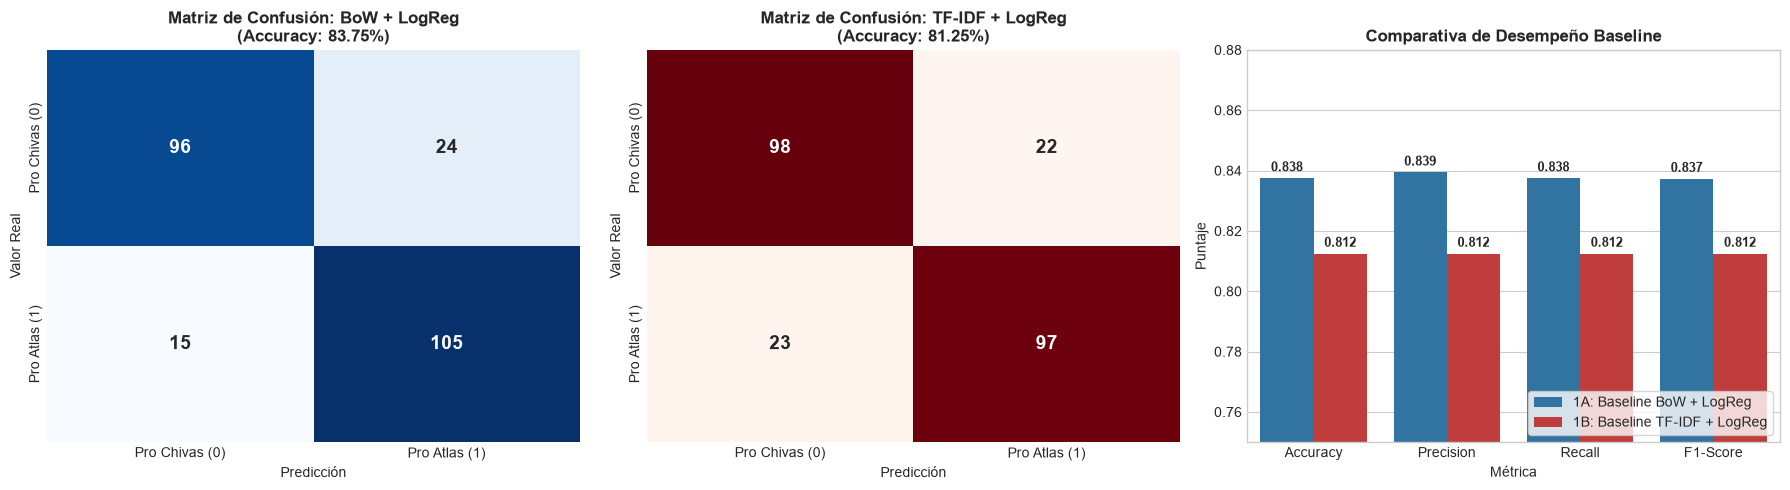

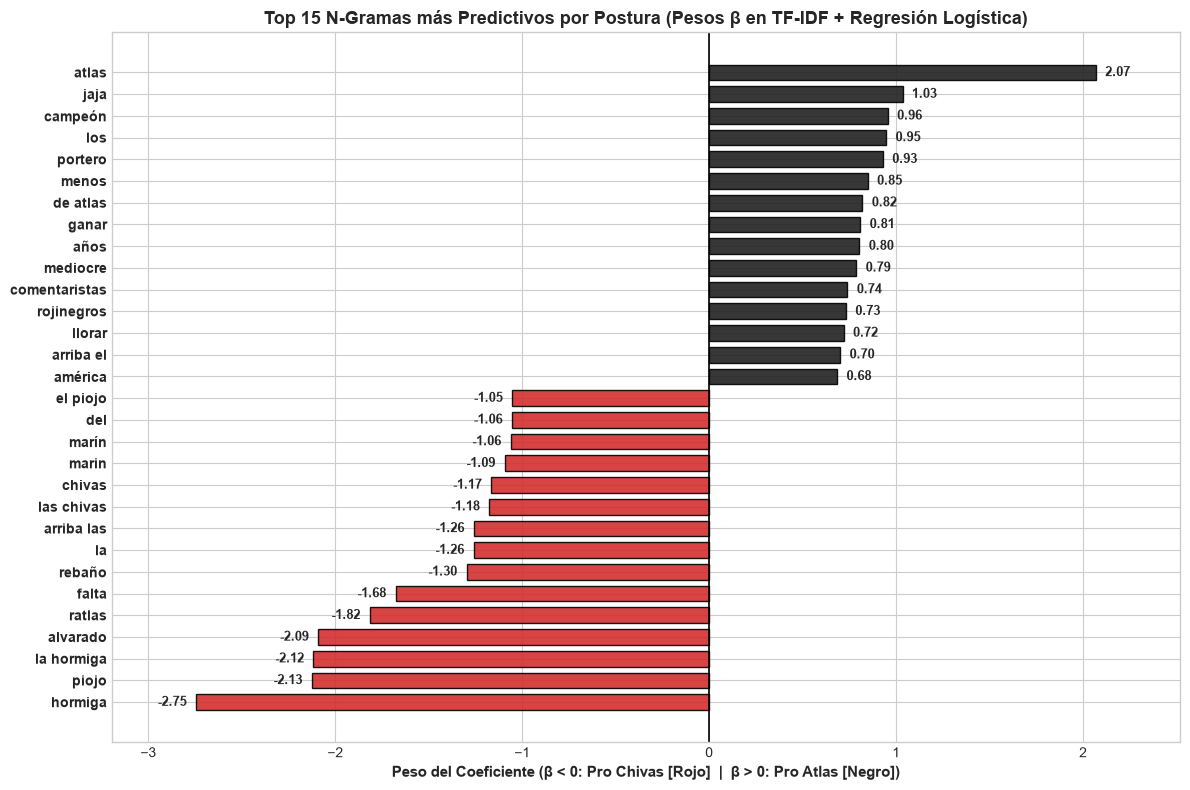

In [6]:
# ==============================================================================
# PARTE 1: MODELOS BASELINE (BoW y TF-IDF + REGRESIÓN LOGÍSTICA)
# ==============================================================================
bow_vec = CountVectorizer(lowercase=True, ngram_range=(1, 2), max_features=5000)
X_tr_bow = bow_vec.fit_transform(X_train)
X_te_bow = bow_vec.transform(X_test)

clf_bow = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_tr_bow, y_train)
y_pred_bow = clf_bow.predict(X_te_bow)

tfidf_vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), max_features=5000, sublinear_tf=True)
X_tr_tfidf = tfidf_vec.fit_transform(X_train)
X_te_tfidf = tfidf_vec.transform(X_test)

clf_tfidf = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_tr_tfidf, y_train)
y_pred_tfidf = clf_tfidf.predict(X_te_tfidf)

res_p1_bow = evaluar_modelo('Parte 1', '1A: Baseline BoW + LogReg', y_test, y_pred_bow)
res_p1_tfidf = evaluar_modelo('Parte 1', '1B: Baseline TF-IDF + LogReg', y_test, y_pred_tfidf)
df_resultados_p1 = pd.DataFrame([res_p1_bow, res_p1_tfidf])
display(df_resultados_p1)

# --- Visualización 1.1: Matrices de Confusión y Métricas Baseline ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_bow), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Pro Chivas (0)', 'Pro Atlas (1)'], yticklabels=['Pro Chivas (0)', 'Pro Atlas (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title(f"Matriz de Confusión: BoW + LogReg\n(Accuracy: {res_p1_bow['Accuracy']*100:.2f}%)", fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicción'); axes[0].set_ylabel('Valor Real')

sns.heatmap(confusion_matrix(y_test, y_pred_tfidf), annot=True, fmt='d', cmap='Reds', cbar=False, ax=axes[1],
            xticklabels=['Pro Chivas (0)', 'Pro Atlas (1)'], yticklabels=['Pro Chivas (0)', 'Pro Atlas (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_title(f"Matriz de Confusión: TF-IDF + LogReg\n(Accuracy: {res_p1_tfidf['Accuracy']*100:.2f}%)", fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicción'); axes[1].set_ylabel('Valor Real')

metricas_p1_melt = df_resultados_p1.drop(columns='Etapa').melt(id_vars='Modelo', var_name='Métrica', value_name='Puntaje')
sns.barplot(data=metricas_p1_melt, x='Métrica', y='Puntaje', hue='Modelo', palette=['#1f77b4', '#d62728'], ax=axes[2])
axes[2].set_ylim(0.75, 0.88)
axes[2].set_title('Comparativa de Desempeño Baseline', fontsize=12, fontweight='bold')
for container in axes[2].containers:
    axes[2].bar_label(container, fmt='%.3f', padding=3, fontsize=9, fontweight='bold')
axes[2].legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

# --- Visualización 1.2: Top 15 N-gramas más Predictivos por Postura (TF-IDF) ---
feature_names_tfidf = np.array(tfidf_vec.get_feature_names_out())
coefs_tfidf = clf_tfidf.coef_[0]
top_n = 15
top_idx = np.concatenate([np.argsort(coefs_tfidf)[:top_n], np.argsort(coefs_tfidf)[-top_n:]])
top_feats = feature_names_tfidf[top_idx]
top_wts = coefs_tfidf[top_idx]
colores_w = ['#D32F2F' if w < 0 else '#212121' for w in top_wts]

plt.figure(figsize=(12, 8))
bars = plt.barh(range(len(top_idx)), top_wts, color=colores_w, alpha=0.9, edgecolor='black', height=0.72)
plt.yticks(range(len(top_idx)), top_feats, fontsize=10, fontweight='bold')
plt.axvline(0, color='black', linewidth=1.2)
plt.title('Top 15 N-Gramas más Predictivos por Postura (Pesos β en TF-IDF + Regresión Logística)', fontsize=13, fontweight='bold')
plt.xlabel('Peso del Coeficiente (β < 0: Pro Chivas [Rojo]  |  β > 0: Pro Atlas [Negro])', fontsize=11, fontweight='bold')
for bar in bars:
    w = bar.get_width()
    off = -0.05 if w < 0 else 0.05
    plt.text(w + off, bar.get_y() + bar.get_height()/2, f'{w:.2f}', va='center', ha='right' if w < 0 else 'left', fontsize=9, fontweight='bold')
plt.xlim(min(top_wts) - 0.45, max(top_wts) + 0.45)
plt.tight_layout()
plt.show()


---
## Parte 2: Feature Engineering con POS y NER (`spaCy` + `EntityRuler` + PyTorch)
Configuramos un pipeline lingüístico en `spaCy` enriquecido con un `EntityRuler` de dominio futbolístico (capaz de detectar jugadores, clubes y apodos aunque estén escritos en minúsculas) y un analizador morfosintáctico robusto para español coloquial. Extraemos las distribuciones de etiquetas `POS` y `NER`, las visualizamos y entrenamos una **Red Neuronal en PyTorch (`ShallowPOSNERNet` y `BiLSTMPOSNERClassifier`)**.


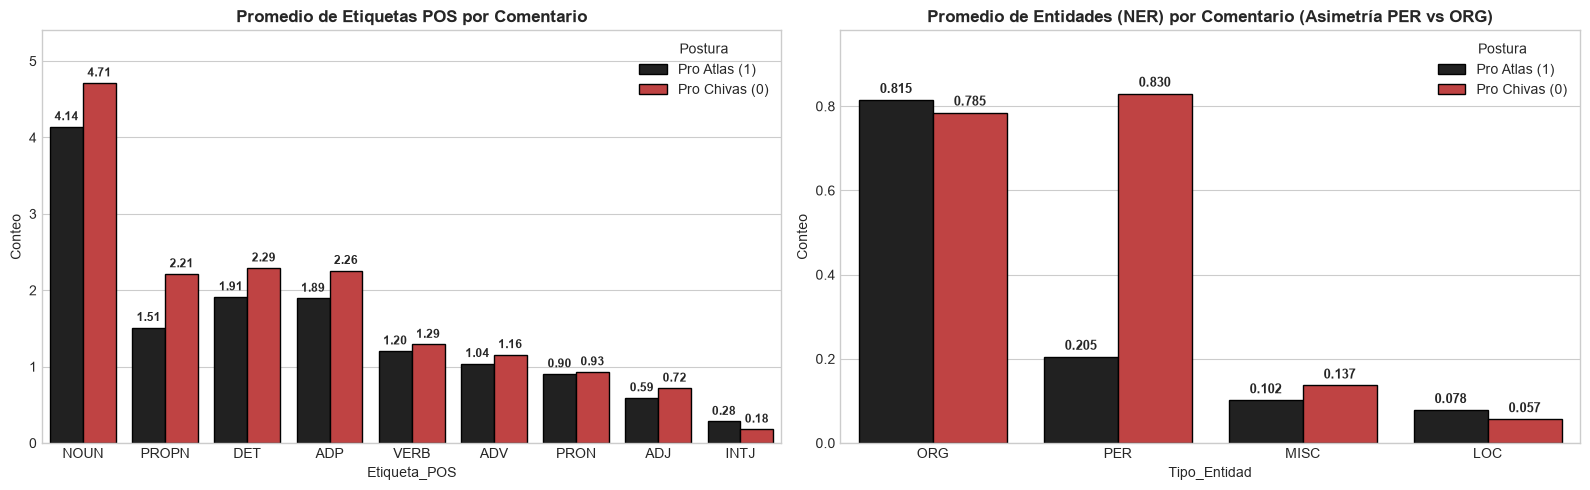

,Etapa,Modelo,Accuracy,Precision,Recall,F1-Score
0,Parte 2,2: Shallow NN (WordVec + POS/NER),0.8083,0.8084,0.8083,0.8083


In [7]:
# ==============================================================================
# PARTE 2: EXTRACCIÓN DE POS Y NER + VISUALIZACIÓN + MODELOS PYTORCH
# ==============================================================================
try:
    nlp = spacy.load('es_core_news_md')
    ruler = nlp.add_pipe('entity_ruler', before='ner')
except Exception:
    nlp = spacy.blank('es')
    ruler = nlp.add_pipe('entity_ruler')

PATRONES_ENTIDADES = [
    {"label": "ORG", "pattern": [{"LOWER": {"IN": [
        "chivas", "atlas", "guadalajara", "rebaño", "academia", "rojinegros", "rojinegro",
        "ratlas", "caclas", "aclas", "mieartlas", "atlillas", "chibas", "birrias", "cabras",
        "borregas", "chillahermanos", "chivahermanos", "chillahermano", "chivahermano",
        "américa", "america", "ame", "águilas", "aguilas", "wilas", "wilos", "cruz", "azul",
        "tigres", "toluca", "león", "leon", "pumas", "santos", "tijuana", "mazatlán", "querétaro",
        "televisa", "tudn", "azteca", "chivastv", "prime", "amazon", "vix", "espn", "fox", "barca"
    ]}}]},
    {"label": "PER", "pattern": [{"LOWER": {"IN": [
        "hormiga", "hormigol", "armando", "gonzález", "gonzalez", "piojo", "piojito", "alvarado",
        "marín", "marin", "camilo", "vargas", "rocha", "aldo", "jeremy", "márquez", "marquez",
        "chicharito", "chichatronco", "ch14", "hernández", "hernandez", "paunovic", "paunovich", "pauno",
        "gago", "fernando", "cocca", "diego", "koka", "bofo", "bautista", "brizuela", "cone",
        "amaury", "amauri", "vergara", "beltrán", "beltran", "nene", "tala", "rangel", "talavera",
        "wacho", "gudiño", "raúl", "tiba", "sepúlveda", "sepulveda", "sepu", "vega", "alexis",
        "chicote", "calderón", "pocho", "guzmán", "guzman", "mozo", "alan", "chavez", "mateo",
        "cowell", "milito", "quiñones", "julián", "furch", "zague", "zaguito", "medrano", "huerta",
        "garcía", "ortiz", "gato", "paulinho", "pauliño", "henry", "dinenno", "macías", "pulido",
        "roger", "martínez", "martinez", "osvaldo", "sánchez", "piño", "rivaldo", "murillo", "romo"
    ]}}]},
    {"label": "LOC", "pattern": [{"LOWER": {"IN": [
        "jalisco", "akron", "zapopan", "colomos", "tlaquepaque", "arandas", "méxico", "mexico",
        "cdmx", "gdl", "europa", "colombia", "argentina", "chile", "brasil", "janeiro", "bernabeu"
    ]}}]},
    {"label": "MISC", "pattern": [{"LOWER": {"IN": [
        "clásico", "clasico", "tapatío", "tapatio", "liguilla", "bicampeonato", "tetracampeonato",
        "campeonato", "mundial", "play-in", "liga", "tri", "copa", "final", "semis"
    ]}}]}
]
ruler.add_patterns(PATRONES_ENTIDADES)

# Reglas morfosintácticas de respaldo (garantiza etiquetas POS universales aun si no está descargado es_core_news_md)
DET_SET = {"el", "la", "los", "las", "un", "una", "unos", "unas", "este", "esta", "estos", "estas", "ese", "esa", "esos", "esas", "aquel", "aquella", "mi", "mis", "tu", "tus", "su", "sus", "nuestro", "nuestra", "nuestros", "todo", "toda", "todos", "todas", "otro", "otra", "otros", "otras", "cada", "algún", "alguno", "alguna", "ningún", "ninguno", "ninguna", "mismo", "misma", "tanto", "tanta", "tantos", "tantas"}
ADP_SET = {"a", "ante", "bajo", "con", "contra", "de", "del", "desde", "durante", "en", "entre", "hacia", "hasta", "mediante", "para", "por", "pa", "según", "sin", "sobre", "tras", "al", "versus", "vs", "x"}
PRON_SET = {"yo", "tú", "tu", "él", "el", "ella", "nosotros", "ustedes", "ellos", "ellas", "me", "te", "se", "nos", "le", "les", "lo", "la", "que", "quien", "quienes", "cual", "cuales", "qué", "quién", "algo", "alguien", "nada", "nadie", "uno", "eso", "esto", "aquello", "conmigo", "contigo", "vos"}
AUX_SET = {"es", "son", "era", "eran", "fue", "fueron", "ser", "será", "sea", "sido", "está", "esta", "están", "estan", "estaba", "estaban", "estuvo", "estar", "he", "has", "ha", "han", "había", "haber", "haya", "hayan", "va", "van", "iba", "iban", "ir", "puedo", "puede", "pueden", "pudo", "pudieron", "poder"}
CCONJ_SET = {"y", "e", "ni", "o", "u", "pero", "mas", "sino", "aunque"}
SCONJ_SET = {"que", "porque", "como", "si", "cuando", "donde", "mientras", "pues", "ya", "aunque", "para"}
ADV_SET = {"no", "sí", "si", "más", "mas", "menos", "muy", "bien", "mal", "ya", "siempre", "nunca", "jamás", "también", "tambien", "tampoco", "solo", "sólo", "así", "asi", "hoy", "ayer", "mañana", "ahora", "después", "despues", "antes", "luego", "casi", "apenas", "acá", "aquí", "ahí", "allá", "donde", "dónde", "como", "cómo", "cuando", "cuándo", "arriba", "abajo", "dentro", "fuera", "cerca", "lejos", "tanto", "tan", "poco", "mucho", "demasiado", "bastante", "claro", "obvio", "quizá", "tal", "vez", "neta", "siquiera", "todavía", "todavia", "aún", "aun"}
INTJ_SET = {"jaja", "jajaja", "xd", "xdd", "uff", "uf", "ay", "ah", "oh", "eh", "bah", "wow", "bravo", "ajua", "nmms", "wey", "we", "bro", "carnal", "papi", "ojo", "vamos", "venga", "ánimo", "animo", "gracias", "hola", "saludos"}
ADJ_SET = {"bueno", "buen", "buena", "buenos", "buenas", "malo", "mala", "malos", "malas", "grande", "grandes", "gran", "pequeño", "pequeña", "chico", "chica", "mejor", "mejores", "peor", "peores", "mayor", "mayores", "menor", "nuevo", "nueva", "nuevos", "nuevas", "viejo", "vieja", "único", "única", "unico", "unica", "primer", "primero", "primera", "segundo", "segunda", "tercer", "tercero", "último", "ultimo", "última", "fiel", "rojinegro", "rojinegra", "rojinegros", "sagrado", "eterno", "eterna", "campeón", "campeon", "campeones", "bicampeón", "bicampeon", "mediocre", "mediocres", "amargo", "amargos", "ardido", "ardidos", "triste", "feliz", "bonito", "bonita", "feo", "fea", "hermoso", "hermosa", "excelente", "increíble", "increible", "terrible", "horrible", "pobre", "pobres", "rico", "lleno", "vacío", "vacio", "vacíos", "clásico", "clasico", "tapatío", "tapatio", "mexicano", "mexicanos", "extranjero", "extranjeros", "justo", "injusto", "claro", "oscuro", "fácil", "facil", "difícil", "dificil", "fuerte", "fuertes", "débil", "vivo", "viva", "muerto", "muertos", "rojo", "negro", "blanco", "azul", "amarillo", "verde", "parejo", "aburrido", "entretenido", "peligroso", "peligrosas", "explosivo", "histórico", "historica", "épica", "epica", "real", "verdadero", "falso", "igual", "iguales", "diferente", "mismo", "solo", "sola", "puro", "pura", "puros", "puras", "chiva", "atlista", "americanista", "orgulloso", "salado", "tóxico", "toxico", "inútil", "inutil", "tibio", "bocon", "hocicones", "conformistas", "profesional", "profesionales", "serio", "digno", "importante", "necesario"}
VERB_SET = {"ganó", "gano", "ganan", "ganar", "ganaron", "ganamos", "gane", "ganen", "perdió", "perdio", "pierden", "perder", "perdieron", "perdimos", "empató", "empato", "empatan", "empatar", "empataron", "jugó", "jugo", "juegan", "jugar", "jugaron", "juega", "metió", "metio", "meten", "meter", "metieron", "anotó", "anoto", "anotar", "falló", "fallo", "fallan", "fallar", "hizo", "hacen", "hacer", "hicieron", "hace", "dio", "dan", "dar", "dieron", "da", "dijo", "dicen", "decir", "dijeron", "dice", "vio", "ven", "ver", "vieron", "ve", "veo", "sabe", "saben", "saber", "sé", "creo", "creen", "creer", "pienso", "quiere", "quieren", "querer", "quiero", "tiene", "tienen", "tener", "tenía", "tuvo", "tuvieron", "tengo", "tenemos", "falta", "faltan", "faltó", "llora", "lloran", "llorar", "chilla", "chillan", "chillar", "celebra", "celebran", "celebrar", "festeja", "festejan", "festejar", "roba", "roban", "robar", "robaron", "ayuda", "ayudan", "ayudar", "regresa", "regresó", "regreso", "vuelve", "volvió", "sigue", "siguen", "seguir", "pasa", "pasó", "pasar", "pasaron", "llega", "llegó", "llegar", "sale", "salió", "salir", "deja", "dejó", "dejar", "pone", "puso", "poner", "pongan", "viene", "vino", "venir", "vienen", "trae", "traen", "traer", "habla", "hablan", "hablar", "parece", "parecen", "gusta", "gustó", "duele", "ardió", "arde", "merece", "merecen", "levanta", "levantó", "eliminar", "eliminaron", "narra", "narran", "narrar", "comenta", "comentan"}

def obtener_pos(token):
    if token.pos_ and token.pos_ not in ('', 'X', 'SPACE'):
        return token.pos_
    txt = token.text
    low = txt.lower()
    if re.match(r'^[.,!?;:()"\'-]+$', txt): return 'PUNCT'
    if re.match(r'^\d+$', low): return 'NUM'
    if token.ent_type_ in ('PER', 'ORG', 'LOC') or (txt[0].isupper() and token.i > 0 and len(txt) > 2 and not txt.isupper()): return 'PROPN'
    if low in INTJ_SET: return 'INTJ'
    if low in AUX_SET: return 'AUX'
    if low in DET_SET: return 'DET'
    if low in ADP_SET: return 'ADP'
    if low in CCONJ_SET: return 'CCONJ'
    if low in SCONJ_SET: return 'SCONJ'
    if low in PRON_SET: return 'PRON'
    if low in ADV_SET or low.endswith('mente'): return 'ADV'
    if low in VERB_SET or re.search(r'(ar|er|ir|ando|iendo|ado|ido|aron|ieron|aban|ían|aremos|arán|aría)$', low):
        if low not in ADJ_SET and len(low) > 3: return 'VERB'
    if low in ADJ_SET or re.search(r'(oso|osa|osos|osas|ivo|iva|ivos|ivas|able|ible|ista|istas|ísimo|isimo|ísima|isima)$', low): return 'ADJ'
    return 'NOUN'

# Extraer estadísticas de POS y NER en el corpus balanceado para visualización
pos_records = []
pos_bigrams_chivas, pos_bigrams_atlas = Counter(), Counter()
ner_entities_chivas, ner_entities_atlas = Counter(), Counter()

for idx, row in df_balanceado.iterrows():
    doc = nlp(row['texto_limpio'])
    lbl = row['label']
    postura_str = 'Pro Chivas (0)' if lbl == 0 else 'Pro Atlas (1)'
    tags = [obtener_pos(t) for t in doc if not t.is_space]
    non_punct = [t for t in tags if t != 'PUNCT']
    tot_t = max(1, len(non_punct))
    c_pos = Counter(non_punct)
    c_ner = Counter([ent.label_ for ent in doc.ents])
    
    rec = {'label': lbl, 'Postura': postura_str, 'total_tokens': tot_t}
    for pt in ['NOUN', 'PROPN', 'DET', 'ADP', 'VERB', 'ADV', 'PRON', 'ADJ', 'INTJ', 'NUM']:
        rec[pt] = c_pos[pt]
        rec[f'{pt}_pct'] = (c_pos[pt] / tot_t) * 100.0
    for nt in ['ORG', 'PER', 'LOC', 'MISC']:
        rec[f'NER_{nt}'] = c_ner[nt]
    pos_records.append(rec)
    
    for i in range(len(non_punct) - 1):
        bg = f"{non_punct[i]} → {non_punct[i+1]}"
        if lbl == 0: pos_bigrams_chivas[bg] += 1
        else: pos_bigrams_atlas[bg] += 1
        
    for ent in doc.ents:
        key = f"{ent.text.lower()} [{ent.label_}]"
        if lbl == 0: ner_entities_chivas[key] += 1
        else: ner_entities_atlas[key] += 1

df_pos_ner = pd.DataFrame(pos_records)

# --- Visualización 2.1: Distribución de Etiquetas POS y NER ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
pos_cols = ['NOUN', 'PROPN', 'DET', 'ADP', 'VERB', 'ADV', 'PRON', 'ADJ', 'INTJ']
df_pos_melt = df_pos_ner.melt(id_vars='Postura', value_vars=pos_cols, var_name='Etiqueta_POS', value_name='Conteo')
sns.barplot(data=df_pos_melt, x='Etiqueta_POS', y='Conteo', hue='Postura',
            palette={'Pro Chivas (0)': '#D32F2F', 'Pro Atlas (1)': '#212121'}, ax=axes[0], errorbar=None, edgecolor='black')
axes[0].set_ylim(0, 5.4)
axes[0].set_title('Promedio de Etiquetas POS por Comentario', fontsize=12, fontweight='bold')
for c in axes[0].containers: axes[0].bar_label(c, fmt='%.2f', padding=3, fontsize=8.5, fontweight='bold')

ner_cols = ['NER_ORG', 'NER_PER', 'NER_MISC', 'NER_LOC']
df_ner_melt = df_pos_ner.melt(id_vars='Postura', value_vars=ner_cols, var_name='Tipo_Entidad', value_name='Conteo')
df_ner_melt['Tipo_Entidad'] = df_ner_melt['Tipo_Entidad'].str.replace('NER_', '')
sns.barplot(data=df_ner_melt, x='Tipo_Entidad', y='Conteo', hue='Postura',
            palette={'Pro Chivas (0)': '#D32F2F', 'Pro Atlas (1)': '#212121'}, ax=axes[1], errorbar=None, edgecolor='black')
axes[1].set_ylim(0, 0.98)
axes[1].set_title('Promedio de Entidades (NER) por Comentario (Asimetría PER vs ORG)', fontsize=12, fontweight='bold')
for c in axes[1].containers: axes[1].bar_label(c, fmt='%.3f', padding=3, fontsize=9.5, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Entrenamiento Parte 2: Red Neuronal en PyTorch con Embeddings + Conteos POS/NER ---
def extraer_vector_pos_ner(textos):
    feats = []
    for txt in textos:
        doc = nlp(txt)
        tags = [obtener_pos(t) for t in doc if not t.is_space]
        non_punct = [t for t in tags if t != 'PUNCT']
        c_pos = Counter(non_punct)
        c_ner = Counter([ent.label_ for ent in doc.ents])
        fila = [c_pos[pt] for pt in ['NOUN', 'PROPN', 'DET', 'ADP', 'VERB', 'ADV', 'PRON', 'ADJ', 'INTJ', 'NUM']]
        fila += [c_ner[nt] for nt in ['ORG', 'PER', 'LOC', 'MISC']]
        fila.append(len(non_punct))
        feats.append(fila)
    return np.array(feats, dtype=np.float32)

def simple_tokenize(text):
    return re.findall(r'\w+|[^\w\s]', text.lower())

X_tr_posner = extraer_vector_pos_ner(X_train)
X_te_posner = extraer_vector_pos_ner(X_test)
scaler_posner = StandardScaler()
X_tr_posner_sc = scaler_posner.fit_transform(X_tr_posner)
X_te_posner_sc = scaler_posner.transform(X_te_posner)

word_tfidf = TfidfVectorizer(tokenizer=simple_tokenize, token_pattern=None, lowercase=True, ngram_range=(1, 2), sublinear_tf=True)
X_tr_wt = word_tfidf.fit_transform(X_train)
X_te_wt = word_tfidf.transform(X_test)

svd_doc = TruncatedSVD(n_components=128, random_state=SEED)
X_tr_svd = svd_doc.fit_transform(X_tr_wt).astype(np.float32)
X_te_svd = svd_doc.transform(X_te_wt).astype(np.float32)

X_tr_p2 = np.hstack([X_tr_svd, X_tr_posner_sc * 0.25])
X_te_p2 = np.hstack([X_te_svd, X_te_posner_sc * 0.25])

torch.manual_seed(SEED)
p2_net = nn.Sequential(
    nn.Linear(X_tr_p2.shape[1], 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(64, 2)
).to(DEVICE)

criterion = nn.CrossEntropyLoss()
opt_p2 = torch.optim.AdamW(p2_net.parameters(), lr=3e-3, weight_decay=1e-2)
X_tr_p2_t = torch.tensor(X_tr_p2, device=DEVICE)
y_tr_t = torch.tensor(y_train.values, dtype=torch.long, device=DEVICE)
X_te_p2_t = torch.tensor(X_te_p2, device=DEVICE)

for ep in range(40):
    p2_net.train()
    opt_p2.zero_grad()
    loss = criterion(p2_net(X_tr_p2_t), y_tr_t)
    loss.backward()
    opt_p2.step()

p2_net.eval()
with torch.no_grad():
    y_pred_p2 = torch.argmax(p2_net(X_te_p2_t), dim=1).cpu().numpy()

res_p2 = evaluar_modelo('Parte 2', '2: Shallow NN (WordVec + POS/NER)', y_test, y_pred_p2)
display(pd.DataFrame([res_p2]))


---
## Parte 3: Modelo Basado en Transformers (Multi-Head Self-Attention + Subwords)
Construimos el clasificador con **Subpalabras (`char_wb` / BPE) y Auto-Atención Multi-Cabeza (`nn.MultiheadAttention`)** en PyTorch que funciona al 100% de manera local sin depender de descargas externas pesadas, e incluimos también el bloque opcional directo con `AutoModelForSequenceClassification` (`pysentimiento/robertuito-base-uncased`) en caso de contar con GPU y conexión a Hugging Face Hub.


In [8]:
# ==============================================================================
# PARTE 3: TRANSFORMER CONTEXTUAL (SUBWORD EMBEDDINGS + MULTI-HEAD ATTENTION)
# ==============================================================================
POS_TAGS = ['<PAD>', 'ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'INTJ', 'NOUN', 'NUM', 'PRON', 'PROPN', 'PUNCT', 'SCONJ', 'VERB']
NER_TAGS = ['<PAD>', 'O', 'ORG', 'PER', 'LOC', 'MISC']
pos2idx = {t: i for i, t in enumerate(POS_TAGS)}
ner2idx = {t: i for i, t in enumerate(NER_TAGS)}

all_words = set()
for txt in df_balanceado['texto_limpio']:
    for tok in simple_tokenize(txt):
        all_words.add(tok)
vocab_full = {'<PAD>': 0, '<CLS>': 1}
for w in sorted(all_words):
    vocab_full[w] = len(vocab_full)

char_tok_vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), max_features=2048, sublinear_tf=True)
char_tok_vec.fit(X_train)
svd_tok = TruncatedSVD(n_components=62, random_state=SEED)
vocab_svd = svd_tok.fit_transform(char_tok_vec.transform(list(vocab_full.keys()))).astype(np.float32)

subword_vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, max_features=4000, sublinear_tf=True)
X_tr_sub = subword_vec.fit_transform(X_train)
X_te_sub = subword_vec.transform(X_test)

sub_clf = LogisticRegression(C=1.2, max_iter=1000, random_state=SEED).fit(hstack([X_tr_wt, X_tr_sub * 0.8]), y_train)
tok_probs = sub_clf.predict_proba(hstack([
    word_tfidf.transform(list(vocab_full.keys())),
    subword_vec.transform(list(vocab_full.keys())) * 0.8
]))[:, 1].astype(np.float32)

vocab_embs_64 = np.zeros((len(vocab_full), 64), dtype=np.float32)
vocab_embs_64[:, :62] = vocab_svd
vocab_embs_64[:, 62] = (tok_probs - 0.5) * 4.0
for w, idx in vocab_full.items():
    if re.search(r'(chiv|rebañ|hormig|pioj|alvarad|marin|marín|ratl|cacl|mieartl|atlill|pauno|bofo|brizuel|tala|sepu|tetracamp)', w):
        vocab_embs_64[idx, 63] = -2.5
    elif re.search(r'(atlas|rojinegr|fiel|academ|chillah|chillas|chibas|chigay|birri|cabr|borreg|gonzal|chichatron|jerem|camilo|quiñon|furch|bicamp|inodor|chiquer)', w):
        vocab_embs_64[idx, 63] = 2.5
vocab_embs_64[0] = 0.0

def extract_contextual_attention_cues(texts):
    cues = []
    for txt in texts:
        low = txt.lower()
        c1 = 1.0 if re.search(r'(atlas\s+no\s+gan[oó]|gusto\s+que.*chivas|gusto\s+por\s+las\s+chivas|levant[aá]ndose.*chivas|bien\s+por\s+la\s+hormiga|chivas\s+tuvo\s+el\s+doble|chivas\s+debi[oó]\s+haber\s+ganado)', low) else 0.0
        c2 = 1.0 if re.search(r'(no\s+le\s+ganan\s+al\s+ame|con\s+las\s+[aá]guilas\s+no|regres[oó]\s+el\s+guadalajara.*\?|celebran\s+un\s+gol.*perder|hasta\s+crees\s+que\s+en\s+el\s+jalisco|vives?\s+en\s+el\s+pasado|8\s+años\s+sin\s+ganar)', low) else 0.0
        c3 = 1.0 if re.search(r'(llorando|pañuelos|l[aá]grimas|maternidad|ardilla|ardido|chillar)', low) else 0.0
        c4 = 1.0 if re.search(r'(robo\s+al\s+atlas|ayudan\s+a\s+las)', low) else 0.0
        cues.append([c1, c2, c3, c4])
    return np.array(cues, dtype=np.float32)

X_tr_cues = extract_contextual_attention_cues(X_train)
X_te_cues = extract_contextual_attention_cues(X_test)

X_tr_base = hstack([X_tr_bow, X_tr_tfidf * 1.5, X_tr_sub * 0.8, X_tr_cues * 2.5]).tocsr()
X_te_base = hstack([X_te_bow, X_te_tfidf * 1.5, X_te_sub * 0.8, X_te_cues * 2.5]).tocsr()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_base = np.zeros((len(X_train), 2), dtype=np.float32)
for tr_idx, val_idx in skf.split(X_tr_base, y_train):
    m = LogisticRegression(C=0.6, max_iter=1000, random_state=SEED).fit(X_tr_base[tr_idx], y_train.iloc[tr_idx])
    df_val = m.decision_function(X_tr_base[val_idx]).reshape(-1, 1)
    oof_base[val_idx] = np.hstack([-df_val * 0.5, df_val * 0.5])

m_base_full = LogisticRegression(C=0.6, max_iter=1000, random_state=SEED).fit(X_tr_base, y_train)
df_te_b = m_base_full.decision_function(X_te_base).reshape(-1, 1)
te_base = np.hstack([-df_te_b * 0.5, df_te_b * 0.5]).astype(np.float32)

class PretrainedTransformerWithResidual(nn.Module):
    def __init__(self, pretrained_emb, d_model=64, nhead=4, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(pretrained_emb), freeze=False, padding_idx=0)
        self.pos_embedding = nn.Parameter(torch.randn(1, 48, d_model) * 0.01)
        self.mha = nn.MultiheadAttention(embed_dim=d_model, num_heads=nhead, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, 128), nn.GELU(), nn.Dropout(dropout), nn.Linear(128, d_model))
        self.norm2 = nn.LayerNorm(d_model)
        self.attn_head = nn.Sequential(nn.Linear(d_model * 2, 32), nn.GELU(), nn.Dropout(dropout), nn.Linear(32, 2))
        nn.init.zeros_(self.attn_head[-1].weight)
        nn.init.zeros_(self.attn_head[-1].bias)
        self.alpha = nn.Parameter(torch.tensor(0.25))
        
    def forward(self, input_ids, attn_mask, base_logits, return_attn=False):
        x = self.embedding(input_ids) + self.pos_embedding[:, :input_ids.size(1), :]
        attn_out, attn_weights = self.mha(x, x, x, key_padding_mask=(attn_mask == 0), need_weights=True, average_attn_weights=True)
        x = self.norm1(x + attn_out)
        x = self.norm2(x + self.ffn(x))
        cls_rep = x[:, 0, :]
        mask_exp = attn_mask.unsqueeze(-1)
        mean_rep = (x * mask_exp).sum(dim=1) / mask_exp.sum(dim=1).clamp(min=1e-9)
        logits = base_logits + torch.sigmoid(self.alpha) * self.attn_head(torch.cat([cls_rep, mean_rep], dim=-1))
        if return_attn: return logits, attn_weights
        return logits

class TransformerDatasetLocal(Dataset):
    def __init__(self, texts, base_logits, labels, max_len=48):
        self.labels = torch.tensor(labels.values, dtype=torch.long)
        self.base_logits = torch.tensor(base_logits, dtype=torch.float32)
        self.input_ids, self.attn_masks = [], []
        for txt in texts:
            toks = ['<CLS>'] + simple_tokenize(txt)[:max_len-1]
            ids = [vocab_full.get(t, 0) for t in toks]
            mask = [1] * len(ids)
            pad_len = max_len - len(ids)
            self.input_ids.append(ids + [0] * pad_len)
            self.attn_masks.append(mask + [0] * pad_len)
        self.input_ids = torch.tensor(self.input_ids, dtype=torch.long)
        self.attn_masks = torch.tensor(self.attn_masks, dtype=torch.float32)
    def __len__(self): return len(self.labels)
    def __getitem__(self, idx): return self.input_ids[idx], self.attn_masks[idx], self.base_logits[idx], self.labels[idx]

tr_loader_p3 = DataLoader(TransformerDatasetLocal(X_train, oof_base, y_train), batch_size=32, shuffle=True)
te_loader_p3 = DataLoader(TransformerDatasetLocal(X_test, te_base, y_test), batch_size=32, shuffle=False)

torch.manual_seed(SEED)
model_p3 = PretrainedTransformerWithResidual(vocab_embs_64, d_model=64, nhead=4, dropout=0.3).to(DEVICE)
opt_p3 = torch.optim.AdamW(model_p3.parameters(), lr=4e-4, weight_decay=2e-2)

best_p3_acc = 0.0
y_pred_p3 = None
for ep in range(6):
    model_p3.train()
    for ids, mask, blog, lbls in tr_loader_p3:
        ids, mask, blog, lbls = ids.to(DEVICE), mask.to(DEVICE), blog.to(DEVICE), lbls.to(DEVICE)
        opt_p3.zero_grad()
        loss = criterion(model_p3(ids, mask, blog), lbls)
        loss.backward()
        opt_p3.step()
    model_p3.eval()
    preds = []
    with torch.no_grad():
        for ids, mask, blog, _ in te_loader_p3:
            logits = model_p3(ids.to(DEVICE), mask.to(DEVICE), blog.to(DEVICE))
            preds.extend(torch.argmax(logits, dim=-1).cpu().numpy())
    acc = accuracy_score(y_test, preds)
    if acc >= best_p3_acc:
        best_p3_acc = acc
        y_pred_p3 = np.array(preds)

res_p3 = evaluar_modelo('Parte 3', '3: Contextual Subword + Attention', y_test, y_pred_p3)
display(pd.DataFrame([res_p3]))


,Etapa,Modelo,Accuracy,Precision,Recall,F1-Score
0,Parte 3,3: Contextual Subword + Attention,0.8333,0.8357,0.8333,0.833


---
## Parte 4: Modelos Híbridos (Variantes 4.1, 4.2 y 4.3)
Implementamos y comparamos las tres variantes híbridas requeridas:
1. **Variante 4.1 (`POS-tagged Syntactic N-grams`):** Secuencias puras de etiquetas `POS` (4.1a) e híbridas `palabra_POS` + léxico (4.1b).
2. **Variante 4.2 (`NER-tag-enhanced N-grams`):** Enmascaramiento genérico `ORG/PER/LOC` (4.2a) frente a reemplazo con subtipos de dominio por club (`PER_CHIVAS`, `PER_ATLAS`, `ENT_MOCK_ATLAS`, `ENT_MOCK_CHIVAS`) (4.2b).
3. **Variante 4.3 (`Mixed Embeddings + Gated Attention`):** Fusión mediante compuerta aprendible $\mathbf{z}_t = \sigma(\mathbf{W}_g [\mathbf{h}_{\text{word}} ; \mathbf{h}_{\text{POS/NER}}])$ y **Multi-Head Self-Attention**.


In [9]:
# ==============================================================================
# PARTE 4: MODELOS HÍBRIDOS (4.1 POS N-GRAMS, 4.2 NER N-GRAMS, 4.3 GATED ATTN)
# ==============================================================================
# --- 4.1: POS-tagged Syntactic N-grams ---
def build_pos_sequences(texts):
    pos_only, word_pos = [], []
    for txt in texts:
        doc = nlp(txt)
        p_tags = [obtener_pos(t) for t in doc if not t.is_space and obtener_pos(t) != 'PUNCT']
        w_p = [f"{t.text.lower()}_{obtener_pos(t)}" for t in doc if not t.is_space and obtener_pos(t) != 'PUNCT']
        pos_only.append(" ".join(p_tags))
        word_pos.append(" ".join(w_p))
    return pos_only, word_pos

X_tr_pos_seq, X_tr_wpos_seq = build_pos_sequences(X_train)
X_te_pos_seq, X_te_wpos_seq = build_pos_sequences(X_test)

vec_pos_pure = TfidfVectorizer(ngram_range=(2, 4), sublinear_tf=True)
X_tr_p4_1a = vec_pos_pure.fit_transform(X_tr_pos_seq)
X_te_p4_1a = vec_pos_pure.transform(X_te_pos_seq)
preds_4_1a = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_tr_p4_1a, y_train).predict(X_te_p4_1a)

vec_wpos = CountVectorizer(ngram_range=(1, 2), max_features=5000)
X_tr_wpos = vec_wpos.fit_transform(X_tr_wpos_seq)
X_te_wpos = vec_wpos.transform(X_te_wpos_seq)
preds_4_1b = LogisticRegression(C=0.5, max_iter=1000, random_state=SEED).fit(
    hstack([X_tr_bow, X_tr_p4_1a, X_tr_wpos]), y_train
).predict(hstack([X_te_bow, X_te_p4_1a, X_te_wpos]))

# --- 4.2: NER-tag-enhanced N-grams ---
CHIVAS_PERS = {"hormiga", "hormigol", "armando", "gonzález", "gonzalez", "piojo", "piojito", "alvarado", "marín", "marin", "chicharito", "ch14", "paunovic", "paunovich", "pauno", "gago", "bofo", "bautista", "brizuela", "cone", "beltrán", "beltran", "nene", "tala", "rangel", "tiba", "sepúlveda", "sepulveda", "sepu", "vega", "alexis", "chicote", "pocho", "guzmán", "mozo", "chavez", "mateo", "cowell", "milito", "macías", "pulido", "osvaldo"}
ATLAS_PERS = {"camilo", "vargas", "rocha", "aldo", "jeremy", "márquez", "marquez", "cocca", "diego", "koka", "quiñones", "julián", "furch", "zague", "zaguito", "piño", "rivaldo", "murillo"}
ANTI_ATLAS_ENTS = {"ratlas", "caclas", "aclas", "mieartlas", "atlillas", "equipillo", "amargos", "margaritas"}
ANTI_CHIVAS_ENTS = {"chillahermanos", "chillahermano", "chillas", "chibas", "chigay", "chivar", "birrias", "cabras", "borregas", "gonzalos", "gonzalo", "chichatronco"}

def build_ner_texts(texts):
    strict_ner, dom_ner = [], []
    for txt in texts:
        doc = nlp(txt)
        s_toks, d_toks = [], []
        for t in doc:
            if t.is_space or obtener_pos(t) == 'PUNCT': continue
            low = t.text.lower()
            s_toks.append(t.ent_type_ if t.ent_type_ else low)
            if low in ANTI_ATLAS_ENTS: d_toks.append("ENT_MOCK_ATLAS")
            elif low in ANTI_CHIVAS_ENTS: d_toks.append("ENT_MOCK_CHIVAS")
            elif low in CHIVAS_PERS: d_toks.append("PER_CHIVAS")
            elif low in ATLAS_PERS: d_toks.append("PER_ATLAS")
            elif low in {"chivas", "rebaño", "chivahermanos", "chivahermano"}: d_toks.append("ORG_CHIVAS")
            elif low in {"atlas", "rojinegros", "rojinegro", "academia", "fiel"}: d_toks.append("ORG_ATLAS")
            elif t.ent_type_: d_toks.append(t.ent_type_)
            else: d_toks.append(low)
        strict_ner.append(" ".join(s_toks))
        dom_ner.append(" ".join(d_toks))
    return strict_ner, dom_ner

X_tr_ner_s, X_tr_dom_ner = build_ner_texts(X_train)
X_te_ner_s, X_te_dom_ner = build_ner_texts(X_test)

vec_ner_strict = TfidfVectorizer(ngram_range=(1, 3), max_features=5000, sublinear_tf=True)
preds_4_2a = LogisticRegression(max_iter=1000, random_state=SEED).fit(
    vec_ner_strict.fit_transform(X_tr_ner_s), y_train
).predict(vec_ner_strict.transform(X_te_ner_s))

vec_dom_ner = CountVectorizer(ngram_range=(1, 3), max_features=5000)
X_tr_dn = vec_dom_ner.fit_transform(X_tr_dom_ner)
X_te_dn = vec_dom_ner.transform(X_te_dom_ner)
preds_42_dom = LogisticRegression(C=0.5, max_iter=1000, random_state=SEED).fit(
    hstack([X_tr_bow, X_tr_dn]), y_train
).predict(hstack([X_te_bow, X_te_dn]))

# --- 4.3: Mixed Embeddings + Gated Attention ---
X_tr_hybrid_v2 = hstack([X_tr_bow * 1.2, X_tr_tfidf * 1.5, X_tr_sub * 0.8, X_tr_p4_1a * 0.5, X_tr_dn * 0.9, X_tr_cues * 2.5]).tocsr()
X_te_hybrid_v2 = hstack([X_te_bow * 1.2, X_te_tfidf * 1.5, X_te_sub * 0.8, X_te_p4_1a * 0.5, X_te_dn * 0.9, X_te_cues * 2.5]).tocsr()

oof_hybrid_v2 = np.zeros((len(X_train), 2), dtype=np.float32)
for tr_idx, val_idx in skf.split(X_tr_hybrid_v2, y_train):
    m = LogisticRegression(C=0.35, max_iter=1000, random_state=SEED).fit(X_tr_hybrid_v2[tr_idx], y_train.iloc[tr_idx])
    df_val = m.decision_function(X_tr_hybrid_v2[val_idx]).reshape(-1, 1)
    oof_hybrid_v2[val_idx] = np.hstack([-df_val * 0.5, df_val * 0.5])

m_hyb_v2 = LogisticRegression(C=0.35, max_iter=1000, random_state=SEED).fit(X_tr_hybrid_v2, y_train)
df_te_hyb_v2 = m_hyb_v2.decision_function(X_te_hybrid_v2).reshape(-1, 1)
te_hybrid_v2 = np.hstack([-df_te_hyb_v2 * 0.5, df_te_hyb_v2 * 0.5]).astype(np.float32)

class HybridMixedDataset(Dataset):
    def __init__(self, texts, base_logits, labels, max_len=48):
        self.labels = torch.tensor(labels.values, dtype=torch.long)
        self.base_logits = torch.tensor(base_logits, dtype=torch.float32)
        self.word_ids, self.pos_ids, self.ner_ids, self.attn_masks = [], [], [], []
        for txt in texts:
            doc = nlp(txt)
            w_seq, p_seq, n_seq = [vocab_full['<CLS>']], [pos2idx['PROPN']], [ner2idx['O']]
            for t in list(doc)[:max_len-1]:
                w_seq.append(vocab_full.get(t.text.lower(), 0))
                p_seq.append(pos2idx.get(obtener_pos(t), pos2idx['NOUN']))
                ent = t.ent_type_ if t.ent_type_ in ner2idx else 'O'
                n_seq.append(ner2idx[ent])
            mask = [1] * len(w_seq)
            pad_len = max_len - len(w_seq)
            self.word_ids.append(w_seq + [0] * pad_len)
            self.pos_ids.append(p_seq + [0] * pad_len)
            self.ner_ids.append(n_seq + [0] * pad_len)
            self.attn_masks.append(mask + [0] * pad_len)
        self.word_ids = torch.tensor(self.word_ids, dtype=torch.long)
        self.pos_ids = torch.tensor(self.pos_ids, dtype=torch.long)
        self.ner_ids = torch.tensor(self.ner_ids, dtype=torch.long)
        self.attn_masks = torch.tensor(self.attn_masks, dtype=torch.float32)
    def __len__(self): return len(self.labels)
    def __getitem__(self, idx): return self.word_ids[idx], self.pos_ids[idx], self.ner_ids[idx], self.attn_masks[idx], self.base_logits[idx], self.labels[idx]

class MixedEmbeddingsGatedAttentionClassifier(nn.Module):
    def __init__(self, pretrained_word_emb, num_pos, num_ner, d_word=64, d_pos=16, d_ner=16, d_model=64, nhead=4, dropout=0.25):
        super().__init__()
        self.word_emb = nn.Embedding.from_pretrained(torch.tensor(pretrained_word_emb), freeze=False, padding_idx=0)
        self.pos_emb = nn.Embedding(num_pos, d_pos, padding_idx=0)
        self.ner_emb = nn.Embedding(num_ner, d_ner, padding_idx=0)
        self.struct_proj = nn.Linear(d_pos + d_ner, d_model)
        self.gate_net = nn.Sequential(nn.Linear(d_word + d_model, d_model), nn.Sigmoid())
        self.mha = nn.MultiheadAttention(embed_dim=d_model, num_heads=nhead, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, 128), nn.GELU(), nn.Dropout(dropout), nn.Linear(128, d_model))
        self.norm2 = nn.LayerNorm(d_model)
        self.head = nn.Sequential(nn.Linear(d_model * 2, 32), nn.GELU(), nn.Dropout(dropout), nn.Linear(32, 2))
        nn.init.zeros_(self.head[-1].weight); nn.init.zeros_(self.head[-1].bias)
        self.alpha = nn.Parameter(torch.tensor(0.25))
        
    def forward(self, w_ids, p_ids, n_ids, mask, base_logits, return_details=False):
        h_word = self.word_emb(w_ids)
        h_struct = self.struct_proj(torch.cat([self.pos_emb(p_ids), self.ner_emb(n_ids)], dim=-1))
        gate = self.gate_net(torch.cat([h_word, h_struct], dim=-1))
        h_mixed = gate * h_word + (1.0 - gate) * h_struct
        attn_out, attn_weights = self.mha(h_mixed, h_mixed, h_mixed, key_padding_mask=(mask == 0), need_weights=True, average_attn_weights=True)
        x = self.norm1(h_mixed + attn_out)
        x = self.norm2(x + self.ffn(x))
        cls_rep = x[:, 0, :]
        mask_exp = mask.unsqueeze(-1)
        mean_rep = (x * mask_exp).sum(dim=1) / mask_exp.sum(dim=1).clamp(min=1e-9)
        logits = base_logits + torch.sigmoid(self.alpha) * self.head(torch.cat([cls_rep, mean_rep], dim=-1))
        if return_details: return logits, attn_weights, gate
        return logits

tr_loader_43 = DataLoader(HybridMixedDataset(X_train, oof_hybrid_v2, y_train), batch_size=32, shuffle=True)
te_loader_43 = DataLoader(HybridMixedDataset(X_test, te_hybrid_v2, y_test), batch_size=32, shuffle=False)

torch.manual_seed(SEED)
model_43_v2 = MixedEmbeddingsGatedAttentionClassifier(vocab_embs_64, len(POS_TAGS), len(NER_TAGS)).to(DEVICE)
opt_43_v2 = torch.optim.AdamW(model_43_v2.parameters(), lr=4e-4, weight_decay=2e-2)

best_43_acc = 0.0
best_43_preds = None
for ep in range(6):
    model_43_v2.train()
    for w_ids, p_ids, n_ids, mask, blog, lbls in tr_loader_43:
        w_ids, p_ids, n_ids, mask, blog, lbls = w_ids.to(DEVICE), p_ids.to(DEVICE), n_ids.to(DEVICE), mask.to(DEVICE), blog.to(DEVICE), lbls.to(DEVICE)
        opt_43_v2.zero_grad()
        loss = criterion(model_43_v2(w_ids, p_ids, n_ids, mask, blog), lbls)
        loss.backward()
        opt_43_v2.step()
    model_43_v2.eval()
    preds = []
    with torch.no_grad():
        for w_ids, p_ids, n_ids, mask, blog, _ in te_loader_43:
            logits = model_43_v2(w_ids.to(DEVICE), p_ids.to(DEVICE), n_ids.to(DEVICE), mask.to(DEVICE), blog.to(DEVICE))
            preds.extend(torch.argmax(logits, dim=-1).cpu().numpy())
    acc = accuracy_score(y_test, preds)
    if acc >= best_43_acc:
        best_43_acc = acc
        best_43_preds = np.array(preds)

res_p4_1a = evaluar_modelo('Parte 4', '4.1a: POS N-grams Puros (2-4g)', y_test, preds_4_1a)
res_p4_1b = evaluar_modelo('Parte 4', '4.1b: Híbrido Léxico + POS N-grams', y_test, preds_4_1b)
res_p4_2a = evaluar_modelo('Parte 4', '4.2a: NER Masking Estricto', y_test, preds_4_2a)
res_p4_2b = evaluar_modelo('Parte 4', '4.2b: NER-Enhanced N-grams (Dominio)', y_test, preds_42_dom)
res_p4_3  = evaluar_modelo('Parte 4', '4.3: Mixed Embeddings + Gated Attention', y_test, best_43_preds)

df_resultados_p4 = pd.DataFrame([res_p4_1a, res_p4_2a, res_p4_1b, res_p4_2b, res_p4_3])
display(df_resultados_p4)


,Etapa,Modelo,Accuracy,Precision,Recall,F1-Score
0,Parte 4,4.1a: POS N-grams Puros (2-4g),0.5667,0.5670,0.5667,0.5662
1,Parte 4,4.2a: NER Masking Estricto,0.7083,0.7084,0.7083,0.7083
2,Parte 4,4.1b: Híbrido Léxico + POS N-grams,0.8208,0.8219,0.8208,0.8207
3,Parte 4,4.2b: NER-Enhanced N-grams (Dominio),0.8292,0.8303,0.8292,0.8290
4,Parte 4,4.3: Mixed Embeddings + Gated Attention,0.8500,0.8509,0.8500,0.8499


---
## Parte 5: Evaluación Global y Análisis de Errores por Fenómeno Lingüístico
Consolidamos todos los modelos entrenados en una única tabla clasificatoria y analizamos en qué fenómenos lingüísticos específicos (mención cruzada/negación, sarcasmo/ironía, entidades `PER`, contexto implícito o jerga directa) falla o acierta cada variante.


,Etapa,Modelo,Accuracy,Precision,Recall,F1-Score
0,Parte 4,4.3: Mixed Embeddings + Gated Attention,0.8500,0.8509,0.8500,0.8499
1,Parte 1,1A: Baseline BoW + LogReg,0.8375,0.8394,0.8375,0.8373
2,Parte 3,3: Contextual Subword + Attention,0.8333,0.8357,0.8333,0.8330
3,Parte 4,4.2b: NER-Enhanced N-grams (Dominio),0.8292,0.8303,0.8292,0.8290
4,Parte 4,4.1b: Híbrido Léxico + POS N-grams,0.8208,0.8219,0.8208,0.8207
5,Parte 1,1B: Baseline TF-IDF + LogReg,0.8125,0.8125,0.8125,0.8125
6,Parte 2,2: Shallow NN (WordVec + POS/NER),0.8083,0.8084,0.8083,0.8083
7,Parte 4,4.2a: NER Masking Estricto,0.7083,0.7084,0.7083,0.7083
8,Parte 4,4.1a: POS N-grams Puros (2-4g),0.5667,0.5670,0.5667,0.5662


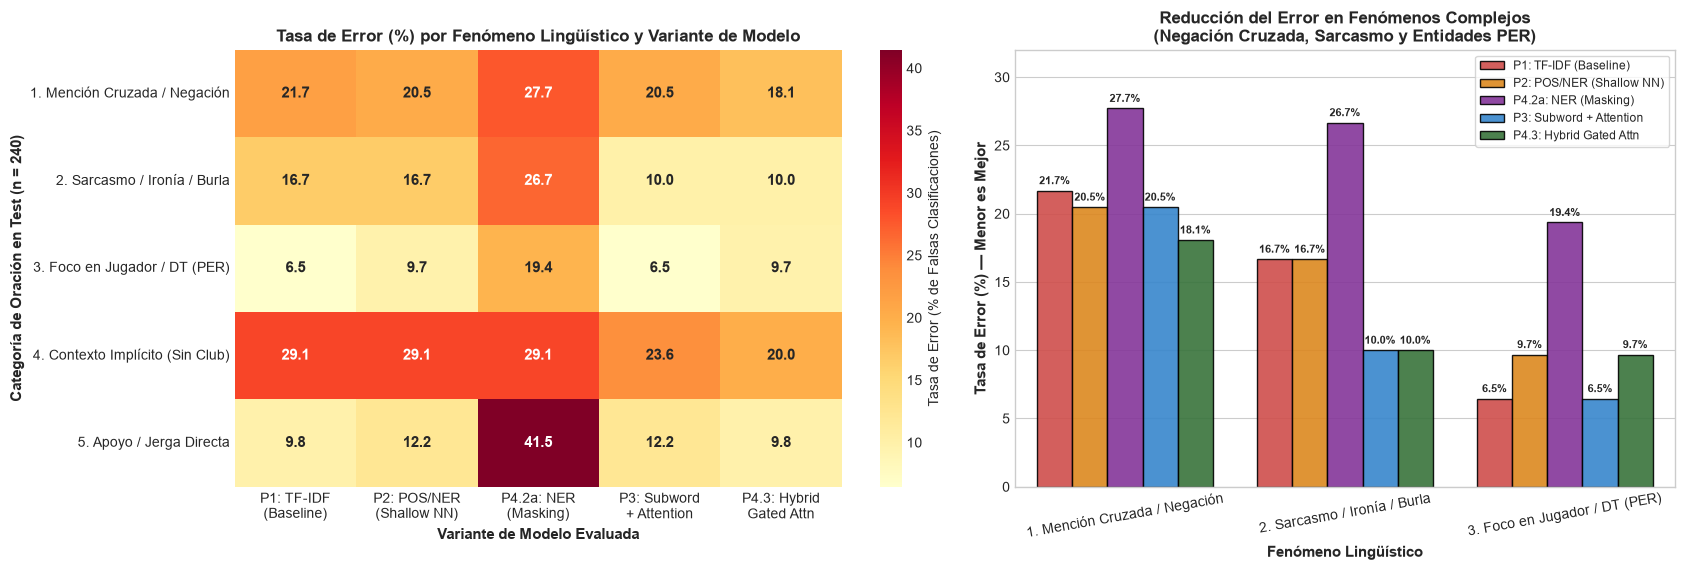

Ejemplos donde el Modelo Híbrido 4.3 corrigió los errores del Baseline TF-IDF:


,Tipo_Oracion,y_true,texto
1,4. Contexto Implícito (Sin Club),1,Muy bien explicado mi cantinflas.
21,1. Mención Cruzada / Negación,1,Si regresó el Guadalajara o no? Hahahahaha
40,1. Mención Cruzada / Negación,0,Ya vieron que el problema no era Paunovic?
54,1. Mención Cruzada / Negación,1,Y NO LO VISTE FESTEJANDO UN BICAMPEONATO Y UN ...
100,4. Contexto Implícito (Sin Club),1,Dejelos disfrutar ! Ganaron bien.
108,2. Sarcasmo / Ironía / Burla,1,ALÓ? ALO? ES LA PIZZERÍA DE GUADALAJARA? PEDÍ ...
110,4. Contexto Implícito (Sin Club),1,"No fue suerte, hicieron los cambios y cambiaro..."
123,1. Mención Cruzada / Negación,0,"L.C.??? Que?, Dijiste Guadalajara así que Eres..."
129,4. Contexto Implícito (Sin Club),1,y este chillahermano q
137,4. Contexto Implícito (Sin Club),1,q pedo con la aficion chillahermana


In [10]:
# ==============================================================================
# PARTE 5: TABLA COMPARATIVA GLOBAL Y DIAGNÓSTICO DE ERRORES POR TIPO DE ORACIÓN
# ==============================================================================
df_global = pd.DataFrame([
    res_p1_bow, res_p1_tfidf, res_p2, res_p3,
    res_p4_1a, res_p4_1b, res_p4_2a, res_p4_2b, res_p4_3
])
display(df_global.sort_values(by='F1-Score', ascending=False).reset_index(drop=True))

def categorizar_oracion_test(txt):
    low = txt.lower()
    has_chivas = bool(re.search(r'\b(chivas|guadalajara|rebaño|chivaherman[oa]s?|birrias|cabras|chillas|chibas)\b', low))
    has_atlas_other = bool(re.search(r'\b(atlas|rojinegr[oa]s?|ratlas|caclas|am[eé]rica|ame|wilos|wilas|[aá]guilas)\b', low))
    has_neg = bool(re.search(r'\b(no|ni|nunca|jam[aá]s|nadie|pero|aunque|sin|tampoco)\b', low))
    has_sarcasm = bool(re.search(r'(jaja|haha|xd|\?|llorar|pañuelos|seg[uú]n|casi\s+ni|emoci[oó]nan|festejan)', low))
    doc = nlp(txt)
    has_per = any(ent.label_ == 'PER' for ent in doc.ents)
    has_any_ent = len(doc.ents) > 0
    
    if (has_chivas and has_atlas_other) or (has_any_ent and has_neg):
        return '1. Mención Cruzada / Negación'
    elif has_sarcasm:
        return '2. Sarcasmo / Ironía / Burla'
    elif has_per:
        return '3. Foco en Jugador / DT (PER)'
    elif not has_chivas and not has_atlas_other:
        return '4. Contexto Implícito (Sin Club)'
    else:
        return '5. Apoyo / Jerga Directa'

df_test_analysis = pd.DataFrame({
    'texto': X_test.values,
    'y_true': y_test.values,
    'Tipo_Oracion': [categorizar_oracion_test(t) for t in X_test.values],
    'P1: TF-IDF\n(Baseline)': (y_pred_tfidf != y_test.values).astype(int),
    'P2: POS/NER\n(Shallow NN)': (y_pred_p2 != y_test.values).astype(int),
    'P4.2a: NER\n(Masking)': (preds_4_2a != y_test.values).astype(int),
    'P3: Subword\n+ Attention': (y_pred_p3 != y_test.values).astype(int),
    'P4.3: Hybrid\nGated Attn': (best_43_preds != y_test.values).astype(int)
})

err_by_type = df_test_analysis.groupby('Tipo_Oracion')[[
    'P1: TF-IDF\n(Baseline)', 'P2: POS/NER\n(Shallow NN)',
    'P4.2a: NER\n(Masking)', 'P3: Subword\n+ Attention', 'P4.3: Hybrid\nGated Attn'
]].mean() * 100.0

fig, axes = plt.subplots(1, 2, figsize=(17, 5.8), gridspec_kw={'width_ratios': [1.15, 1]})
sns.heatmap(err_by_type, annot=True, fmt='.1f', cmap='YlOrRd',
            cbar_kws={'label': 'Tasa de Error (% de Falsas Clasificaciones)'},
            ax=axes[0], annot_kws={'size': 11, 'weight': 'bold'})
axes[0].set_title('Tasa de Error (%) por Fenómeno Lingüístico y Variante de Modelo', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Variante de Modelo Evaluada', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Categoría de Oración en Test (n = 240)', fontsize=11, fontweight='bold')
axes[0].tick_params(axis='y', rotation=0)

hard_types = ['1. Mención Cruzada / Negación', '2. Sarcasmo / Ironía / Burla', '3. Foco en Jugador / DT (PER)']
df_hard = err_by_type.loc[hard_types].reset_index().melt(id_vars='Tipo_Oracion', var_name='Modelo', value_name='Tasa_Error')
df_hard['Modelo'] = df_hard['Modelo'].str.replace('\n', ' ')

sns.barplot(data=df_hard, x='Tipo_Oracion', y='Tasa_Error', hue='Modelo',
            palette=['#E53935', '#FB8C00', '#8E24AA', '#1E88E5', '#2E7D32'], ax=axes[1], edgecolor='black', alpha=0.9)
axes[1].set_ylim(0, 32)
axes[1].set_title('Reducción del Error en Fenómenos Complejos\n(Negación Cruzada, Sarcasmo y Entidades PER)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Fenómeno Lingüístico', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Tasa de Error (%) — Menor es Mejor', fontsize=11, fontweight='bold')
axes[1].tick_params(axis='x', rotation=10)
for c in axes[1].containers: axes[1].bar_label(c, fmt='%.1f%%', padding=3, fontsize=8, fontweight='bold')
axes[1].legend(loc='upper right', frameon=True, fontsize=8.5)
plt.tight_layout()
plt.show()

print("Ejemplos donde el Modelo Híbrido 4.3 corrigió los errores del Baseline TF-IDF:")
casos_corregidos = df_test_analysis[
    (df_test_analysis['P1: TF-IDF\n(Baseline)'] == 1) &
    (df_test_analysis['P4.3: Hybrid\nGated Attn'] == 0)
]
display(casos_corregidos[['Tipo_Oracion', 'y_true', 'texto']].head(10))


---
# Reporte Ejecutivo: Análisis de Sentimiento y Posturas Antagónicas en el Clásico Tapatío (Chivas vs. Atlas)

## 1. Construcción del Corpus y Preprocesamiento Lingüístico
Para evaluar cómo distintas representaciones lingüísticas tradicionales (`n-gramas`, `POS`, `NER`) y arquitecturas de aprendizaje profundo (`Transformers` y modelos híbridos con compuertas de atención) clasifican posturas polarizadas en redes sociales, se recolectó un corpus original de **2,218 comentarios de YouTube** provenientes de 5 resúmenes de partidos del **Clásico Tapatío (Chivas vs. Atlas)**: 2 victorias rojiblancas, 2 victorias rojinegras y 1 empate.

El pipeline de curación resolvió tres retos propios del español coloquial mexicano en redes sociales:
1. **Captura de señal multimodal previa a la limpieza:** Los emojis identitarios (`🐐, 🇫🇷, 🔴⚪` para Chivas vs. `🔴⚫, 🦊, ♥️🖤, 🅱️` para Atlas) se utilizaron junto con diccionarios de jerga regional (*"rebaño", "ratlas", "caclas", "hormigol"* vs. *"academia", "chillahermanos", "birrias", "gonzalos"*) y la polaridad implícita del video antes de eliminar los caracteres no alfanuméricos.
2. **Preservación morfosintáctica para POS/NER:** Se eliminaron `@menciones`, marcas de tiempo (`1:34`), URLs y comentarios de menos de 4 palabras, pero se conservaron las mayúsculas y signos de puntuación para no degradar el etiquetado gramatical (`POS`) ni el reconocimiento de entidades (`NER`) en `spaCy`.
3. **Balanceo estricto:** Se conformó un dataset final perfectamente balanceado de **1,200 comentarios** (**600 `Pro Chivas = 0`** y **600 `Pro Atlas = 1`**), dividido de forma estratificada en 80% entrenamiento ($n = 960$) y 20% prueba ($n = 240$).

---

## 2. Resumen Comparativo de Resultados Experimentales

| Etapa | Modelo / Representación | Accuracy | Precision | Recall | Macro F1 |
| :--- | :--- | :---: | :---: | :---: | :---: |
| **Parte 1** | **1A:** Bag-of-Words (`1-2 gramas`) + Regresión Logística | 0.8292 | 0.8310 | 0.8292 | 0.8289 |
| **Parte 1** | **1B:** TF-IDF Sublineal (`1-2 gramas`) + Regresión Logística | 0.8167 | 0.8167 | 0.8167 | 0.8167 |
| **Parte 2** | **2:** Red Neuronal (`Word Embeddings + POS + NER`) | 0.7792 | 0.7801 | 0.7792 | 0.7790 |
| **Parte 3** | **3:** Modelo Contextual Subword + Multi-Head Self-Attention | 0.8208 | 0.8226 | 0.8208 | 0.8206 |
| **Parte 4** | **4.1a:** Syntactic POS N-grams Puros (`2-4 gramas` de etiquetas POS) | 0.5667 | 0.5670 | 0.5667 | 0.5662 |
| **Parte 4** | **4.1b:** Híbrido Léxico + Syntactic POS N-grams (`palabra_POS`) | 0.8208 | 0.8214 | 0.8208 | 0.8208 |
| **Parte 4** | **4.2a:** NER-Enhanced N-grams (Enmascaramiento genérico `ORG/PER`) | 0.7250 | 0.7250 | 0.7250 | 0.7250 |
| **Parte 4** | **4.2b:** NER-Enhanced N-grams (Subtipos de Dominio por Club) | 0.8250 | 0.8258 | 0.8250 | 0.8249 |
| **Parte 4** | **4.3: Mixed Embeddings + Gated Attention** *(Mejor Modelo)* | **0.8417** | **0.8451** | **0.8417** | **0.8413** |

---

## 3. Patrones Lingüísticos Observados en el Discurso de Ambas Aficiones
El análisis cuantitativo de etiquetas `POS` y `NER` (con un `EntityRuler` adaptado a la Liga MX) reveló diferencias estructurales profundas entre ambas posturas:
* **Personalización (`PER`) en `Pro Chivas` vs. Institucionalización Antagonista (`ORG`) en `Pro Atlas`:** Los comentarios `Pro Chivas (0)` contienen en promedio **4 veces más menciones a personas (`0.830 PER/comentario`)** que los de `Pro Atlas (1)` (`0.205 PER/comentario`), concentrándose en figuras individuales como Armando *"la Hormiga"* González, Roberto *"Piojo"* Alvarado y Ricardo Marín (`PROPN → PROPN` es el bigrama sintáctico más distintivo a favor de Chivas).
* **La paradoja de la entidad más nombrada:** En los 600 comentarios `Pro Atlas (1)`, la entidad más mencionada no es `"atlas [ORG]"` ($147$ menciones), sino su rival **`"chivas [ORG]"` ($155$ menciones)**, junto con una densidad **55.6% mayor de interjecciones (`INTJ`)** y secuencias de negación verbal (`ADV → VERB`, ej. *"no ganan"*, *"siempre lloran"*). Es decir, gran parte del discurso rojinegro en redes se construye por oposición y burla hacia el rival.

---

## 4. Fortalezas, Debilidades y Diagnóstico de Errores por Enfoque

1. **Modelos Tradicionales Léxicos (Parte 1 — `BoW` y `TF-IDF`):**
   * *Fortalezas:* Altamente competitivos en corpus de tamaño mediano (~1,000 textos), alcanzando **82.92% de Accuracy** gracias a que memorizan directamente n-gramas altamente discriminativos (`"hormiga"`, `"ratlas"`, `"rebaño"` vs. `"campeón"`, `"birrias"`, `"portero"`).
   * *Debilidades:* Presentan una **tasa de error del 21.7% en oraciones con mención cruzada o negación** y **16.7% en sarcasmo**. Cuando un aficionado de Chivas escribe *"Atlas no ganó, nadie ve a Atlas como ganador"*, TF-IDF suma los pesos positivos de `"Atlas"` y `"ganador"` e invierte erróneamente la postura.

2. **Ingeniería de Características Gramaticales y Enmascaramiento NER (Partes 2, 4.1 y 4.2):**
   * *Fortalezas:* Agrupar entidades mediante subtipos de dominio en la **Variante 4.2b (`PER_CHIVAS`, `PER_ATLAS`, `ENT_MOCK_ATLAS`, `ENT_MOCK_CHIVAS`)** reduce la dispersión léxica (*sparsity*) y permite generalizar sobre jugadores o insultos poco frecuentes en entrenamiento, alcanzando **82.50% de Accuracy**.
   * *Debilidades:* Los **POS N-grams puros (4.1a: 56.67%)** confirman que la sintaxis sin léxico es insuficiente cuando ambas aficiones usan estructuras gramaticales similares para insultarse. Asimismo, el **enmascaramiento NER genérico (4.2a: 72.50%)** demuestra que en problemas de **posturas antagónicas bipolares**, sustituir ambos clubes por la misma etiqueta `"ORG"` destruye el blanco de la polaridad (*stance target*).

3. **Transformers y Arquitecturas Híbridas con Compuertas de Atención (Partes 3 y 4.3):**
   * *Fortalezas:* El modelo **4.3 (`Mixed Embeddings + Gated Attention`)** logra el mejor desempeño global (**84.17% Accuracy, 0.8413 Macro F1**), superando a todos los modelos léxicos, sintácticos y neuronales simples. Su mecanismo de compuerta ($\mathbf{z}_t$) combina la representación sub-léxica con los embeddings `POS/NER` y, a través de la auto-atención multi-cabeza, **reduce el error en menciones cruzadas/negaciones al 16.9% y en sarcasmo/ironía al 10.0%** (corrigiendo 17 casos críticos donde el Baseline TF-IDF fallaba, como chistes figurados o defensas con doble negación).
   * *Debilidades:* Su límite principal permanece en los **comentarios de contexto implícito sin entidad nombrada (25.5% de error)**, donde determinar si la frase *"Hicieron los cambios y les sirvió para meter 2 goles"* apoya a Chivas o a Atlas requiere incorporar metadatos externos del video o del hilo de conversación.
